# 01 RQ1: crypto vs. non-crypto calibration

Confirmatory test of RQ1 (`docs/hypotheses.md` Section 4) with the estimation
details fixed in D7, then the registered descriptives and the Section 5
sensitivities. Input: `data/processed/mart_analysis.parquet`
(`sql/03_marts/03_mart_analysis.sql`) and `mart_vwap.parquet` (`04_mart_vwap.sql`).

Model per (horizon × format) cell:
`token1_won ~ logit(p) + crypto + crypto × logit(p)`, p clipped to [0.001, 0.999],
CR1 cluster-robust SEs on the Section 3 clusters, z tests, Holm over the six cells.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.special import expit, logit
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning, PerfectSeparationWarning

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

SEED = 20261112          # D7.5
B = 1000                 # bootstrap resamples (Section 4)
CLIP = (0.001, 0.999)    # Section 4
MIN_CLUSTERS = 30        # Section 4
HORIZONS = ["1w", "1d", "1h"]
FORMATS = ["template", "event"]
SUBJECTS = ["crypto", "politics", "sports", "weather", "other"]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

frame = pd.read_parquet(DATA / "mart_analysis.parquet")
vwap = pd.read_parquet(DATA / "mart_vwap.parquet")[["market_id", "horizon", "vwap_price"]]
frame = frame.merge(vwap, on=["market_id", "horizon"], how="left", validate="one_to_one")
frame["y"] = frame["token1_won"].astype(float)
primary = frame[frame["is_primary"]]
primary.groupby("horizon").size()

horizon
1d    351535
1h    371676
1w     78156
dtype: int64

## 1. Confirmatory tests

`fit_cell` fits the registered model in one cell. A fit that fails to converge or
warns of perfect separation is reported as not estimable (D7.1); no substitute model
is fitted. The crypto slope and its SE come from the same fit (b_logit + b_interaction).

The printed table blanks the crypto slope, interaction and p-value of a cell that is not
estimable; `results/rq1_tests.csv` keeps the raw (unconverged) values next to the flag.
A non-estimable cell leaves the Holm family, as an untestable cell does under Section 4.


In [2]:
NAN_FIT = dict(slope_noncrypto=np.nan, se_slope_noncrypto=np.nan, slope_crypto=np.nan,
               se_slope_crypto=np.nan, interaction=np.nan, se_interaction=np.nan,
               ci_low=np.nan, ci_high=np.nan, p_value=np.nan)


def fit_cell(d, price_col="snap_price", cluster_col="cluster_id"):
    d = d[d[price_col].notna()]
    crypto = d["is_crypto"].to_numpy()
    out = {
        "n_crypto": int(crypto.sum()),
        "n_noncrypto": int((~crypto).sum()),
        "clusters_crypto": d.loc[d["is_crypto"], cluster_col].nunique(),
        "clusters_noncrypto": d.loc[~d["is_crypto"], cluster_col].nunique(),
    }
    out["testable"] = min(out["clusters_crypto"], out["clusters_noncrypto"]) >= MIN_CLUSTERS
    if min(out["clusters_crypto"], out["clusters_noncrypto"]) < 2:
        return {**out, "estimable": False, **NAN_FIT}
    x = logit(d[price_col].clip(*CLIP).to_numpy())
    c = crypto.astype(float)
    X = np.column_stack([np.ones_like(x), x, c, c * x])
    groups = pd.factorize(d[cluster_col])[0]
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            res = sm.Logit(d["y"].to_numpy(), X).fit(
                disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": groups}
            )
    except np.linalg.LinAlgError:
        return {**out, "estimable": False, **NAN_FIT}
    separation = any(issubclass(w.category, PerfectSeparationWarning) for w in caught)
    converged = bool(res.mle_retvals["converged"]) and not any(
        issubclass(w.category, ConvergenceWarning) for w in caught
    )
    out["estimable"] = converged and not separation
    b, V = res.params, res.cov_params()
    se_int = np.sqrt(V[3, 3])
    out.update(
        slope_noncrypto=b[1],
        se_slope_noncrypto=np.sqrt(V[1, 1]),
        slope_crypto=b[1] + b[3],
        se_slope_crypto=np.sqrt(V[1, 1] + V[3, 3] + 2 * V[1, 3]),
        interaction=b[3],
        se_interaction=se_int,
        ci_low=b[3] - 1.959964 * se_int,
        ci_high=b[3] + 1.959964 * se_int,
        p_value=res.pvalues[3],
    )
    return out


def run_family(df, price_col="snap_price", cluster_col="cluster_id"):
    rows = []
    for h in HORIZONS:
        for f in FORMATS:
            d = df[(df["horizon"] == h) & (df["format"] == f)]
            rows.append({"horizon": h, "format": f, **fit_cell(d, price_col, cluster_col)})
    return pd.DataFrame(rows)


tests = run_family(primary)
ok = tests["testable"] & tests["estimable"]
tests["p_holm"] = np.nan
tests.loc[ok, "p_holm"] = multipletests(tests.loc[ok, "p_value"], method="holm")[1]
tests["significant_holm"] = tests["p_holm"] < 0.05
tests.to_csv(RESULTS / "rq1_tests.csv", index=False)
print(f"family size: {ok.sum()} tests")
for _, r in tests[~ok].iterrows():
    why = "not estimable (D7.1)" if r["testable"] else "< 30 clusters (Section 4)"
    print(f"excluded from family: {r['horizon']} {r['format']}, {why}")
# The CSV keeps raw estimates beside the flags; the display masks fits that are not estimable.
est_cols = ["slope_crypto", "se_slope_crypto", "interaction", "se_interaction", "ci_low", "ci_high", "p_value"]
tests.assign(**{c: tests[c].where(tests["estimable"]) for c in est_cols}).round(4)

family size: 5 tests
excluded from family: 1h event, not estimable (D7.1)


,horizon,format,n_crypto,n_noncrypto,clusters_crypto,clusters_noncrypto,testable,estimable,slope_noncrypto,se_slope_noncrypto,slope_crypto,se_slope_crypto,interaction,se_interaction,ci_low,ci_high,p_value,p_holm,significant_holm
0,1w,template,5802,9895,161,279,True,True,0.9748,0.0671,0.9265,0.0482,-0.0483,0.0826,-0.2102,0.1137,0.5591,0.5591,False
1,1w,event,2048,60411,741,10568,True,True,0.9637,0.0135,1.1047,0.0690,0.1409,0.0703,0.0031,0.2788,0.0451,0.1352,False
2,1d,template,37122,116701,249,425,True,True,1.0825,0.0142,1.0226,0.0268,-0.0599,0.0304,-0.1194,-0.0004,0.0485,0.1352,False
3,1d,event,2442,195270,816,15852,True,True,0.9804,0.0087,1.3689,0.0908,0.3885,0.0912,0.2098,0.5671,0.0000,0.0001,True
4,1h,template,104289,35182,196,296,True,True,1.3042,0.0421,1.1027,0.0203,-0.2015,0.0467,-0.2931,-0.1099,0.0000,0.0001,True
5,1h,event,869,231336,406,9275,True,False,1.1840,0.0192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


## 2. Descriptives per (horizon × format × subject)

Brier (unclipped p), log loss (clipped p), calibration-in-the-large (offset model,
D7.2), each with a percentile CI from 1,000 cluster resamples within the cell (D7.5).
Means are ratios of cluster sums, so a resample is a multinomial weight per cluster.

In [3]:
rng = np.random.default_rng(SEED)


def cluster_weights(n_clusters):
    return rng.multinomial(n_clusters, np.full(n_clusters, 1 / n_clusters), size=B).astype(float)


def citl(y, o, w, a=0.0):
    for _ in range(100):
        p = expit(a + o)
        step = np.sum(w * (y - p)) / np.sum(w * p * (1 - p))
        a += step
        if abs(step) < 1e-10:
            break
    return a


def describe_cell(d):
    y = d["y"].to_numpy()
    p = d["snap_price"].to_numpy()
    pc = np.clip(p, *CLIP)
    o = logit(pc)
    g, _ = pd.factorize(d["cluster_id"])
    C = g.max() + 1
    sq = (p - y) ** 2
    ll = -(y * np.log(pc) + (1 - y) * np.log(1 - pc))
    n_c = np.bincount(g, minlength=C)
    W = cluster_weights(C)
    brier_b = (W @ np.bincount(g, sq, C)) / (W @ n_c)
    ll_b = (W @ np.bincount(g, ll, C)) / (W @ n_c)
    a_hat = citl(y, o, np.ones_like(y))
    a_b = np.array([citl(y, o, W[i, g], a_hat) for i in range(B)])
    q = lambda v: np.percentile(v, [2.5, 97.5])
    return {
        "n": len(d), "clusters": C,
        "brier": sq.mean(), "brier_lo": q(brier_b)[0], "brier_hi": q(brier_b)[1],
        "log_loss": ll.mean(), "ll_lo": q(ll_b)[0], "ll_hi": q(ll_b)[1],
        "citl": a_hat, "citl_lo": q(a_b)[0], "citl_hi": q(a_b)[1],
    }


rows = []
for h in HORIZONS:
    for f in FORMATS:
        for s in SUBJECTS:
            d = primary[(primary["horizon"] == h) & (primary["format"] == f) & (primary["subject"] == s)]
            if len(d) == 0:
                continue
            rows.append({"horizon": h, "format": f, "subject": s, **describe_cell(d)})
desc = pd.DataFrame(rows)
desc.to_csv(RESULTS / "rq1_descriptives.csv", index=False)
desc.round(4)

,horizon,format,subject,n,clusters,brier,brier_lo,brier_hi,log_loss,ll_lo,ll_hi,citl,citl_lo,citl_hi
0,1w,template,crypto,5802,161,0.0997,0.0838,0.1147,0.3244,0.2757,0.3697,-0.1256,-0.3278,0.1589
1,1w,template,politics,1770,19,0.1413,0.1097,0.1747,0.4301,0.3411,0.5215,-0.3690,-1.1733,0.2229
2,1w,template,weather,353,53,0.0739,0.0587,0.0900,0.2482,0.2000,0.3066,-0.0225,-0.2823,0.2242
3,1w,template,other,7772,207,0.0736,0.0607,0.0967,0.2465,0.2150,0.3068,0.0221,-0.0653,0.1191
4,1w,event,crypto,2048,741,0.0750,0.0622,0.0883,0.2403,0.2035,0.2788,0.1493,-0.0612,0.3804
5,1w,event,politics,11607,3285,0.0791,0.0719,0.0863,0.2534,0.2318,0.2761,-0.0192,-0.1080,0.0844
6,1w,event,sports,25986,1753,0.1566,0.1441,0.1656,0.4702,0.4367,0.4946,-0.1026,-0.1414,-0.0724
7,1w,event,weather,236,43,0.0603,0.0398,0.0741,0.2156,0.1527,0.2588,-0.1794,-0.3810,0.1005
8,1w,event,other,22582,5645,0.0863,0.0809,0.0925,0.2761,0.2615,0.2939,0.0031,-0.0516,0.0569
9,1d,template,crypto,37122,249,0.1042,0.0772,0.1413,0.3101,0.2376,0.4093,0.0359,-0.0359,0.1297


## 3. Calibration curves

Ten equal-width bins (D7.4). Per bin: mean price vs. observed win frequency, with a
cluster-bootstrap 95% CI. The non-crypto curve pools four subjects, so its clusters are
resampled within each subject and pooled (D7.5). Bins with < 30 markets are hollow.
The symmetrized curve (D7.6) uses each market twice, as (p, y) and (1 − p, 1 − y).

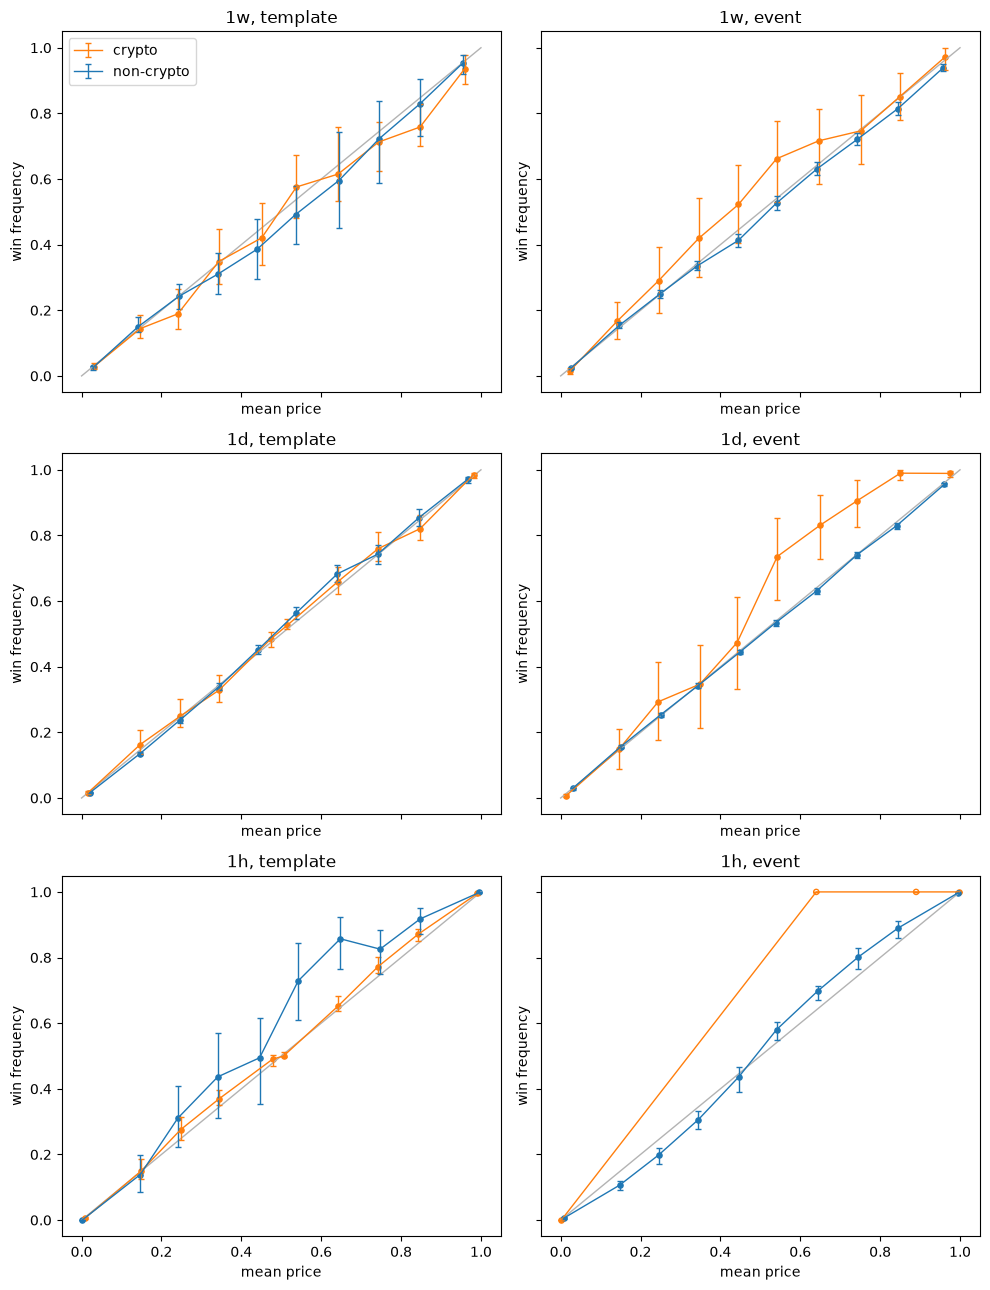

In [4]:
def curve(d, symmetrize=False):
    p = d["snap_price"].to_numpy()
    y = d["y"].to_numpy()
    cl = d["cluster_id"].to_numpy()
    strata = d["subject"].to_numpy()
    if symmetrize:
        p, y, cl, strata = (np.r_[p, 1 - p], np.r_[y, 1 - y], np.r_[cl, cl], np.r_[strata, strata])
    b = np.minimum((p * 10).astype(int), 9)
    num = np.zeros((B, 10)); den = np.zeros((B, 10))
    for s in np.unique(strata):
        m = strata == s
        g, _ = pd.factorize(cl[m])
        C = g.max() + 1
        W = cluster_weights(C)
        Y = np.zeros((C, 10)); N = np.zeros((C, 10))
        np.add.at(Y, (g, b[m]), y[m]); np.add.at(N, (g, b[m]), 1)
        num += W @ Y; den += W @ N
    with np.errstate(invalid="ignore", divide="ignore"):
        freq_b = num / den
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # empty bins: all-NaN columns
        lo, hi = np.nanpercentile(freq_b, [2.5, 97.5], axis=0)
    n_bin = np.bincount(b, minlength=10)
    return pd.DataFrame({
        "bin": np.arange(10),
        "n": n_bin,
        "mean_price": np.bincount(b, p, 10) / np.maximum(n_bin, 1),
        "freq": np.bincount(b, y, 10) / np.maximum(n_bin, 1),
        "lo": lo,
        "hi": hi,
    })


def curve_grid(symmetrize, path):
    fig, axes = plt.subplots(3, 2, figsize=(10, 13), sharex=True, sharey=True)
    tables = []
    for i, h in enumerate(HORIZONS):
        for j, f in enumerate(FORMATS):
            ax = axes[i, j]
            ax.plot([0, 1], [0, 1], color="0.7", lw=1)
            for crypto, color in [(True, "tab:orange"), (False, "tab:blue")]:
                d = primary[(primary["horizon"] == h) & (primary["format"] == f) & (primary["is_crypto"] == crypto)]
                t = curve(d, symmetrize)
                t = t[t["n"] > 0]
                tables.append(t.assign(horizon=h, format=f, crypto=crypto))
                ax.errorbar(t["mean_price"], t["freq"], yerr=[t["freq"] - t["lo"], t["hi"] - t["freq"]],
                            color=color, lw=1, capsize=2, label="crypto" if crypto else "non-crypto")
                thin = t["n"] < 30
                ax.scatter(t.loc[~thin, "mean_price"], t.loc[~thin, "freq"], color=color, s=14)
                ax.scatter(t.loc[thin, "mean_price"], t.loc[thin, "freq"], facecolors="none", edgecolors=color, s=14)
            ax.set_title(f"{h}, {f}")
            ax.set_xlabel("mean price"); ax.set_ylabel("win frequency")
    axes[0, 0].legend()
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    return pd.concat(tables, ignore_index=True)


curves = curve_grid(False, RESULTS / "rq1_curves.png")
curves.to_csv(RESULTS / "rq1_curves.csv", index=False)

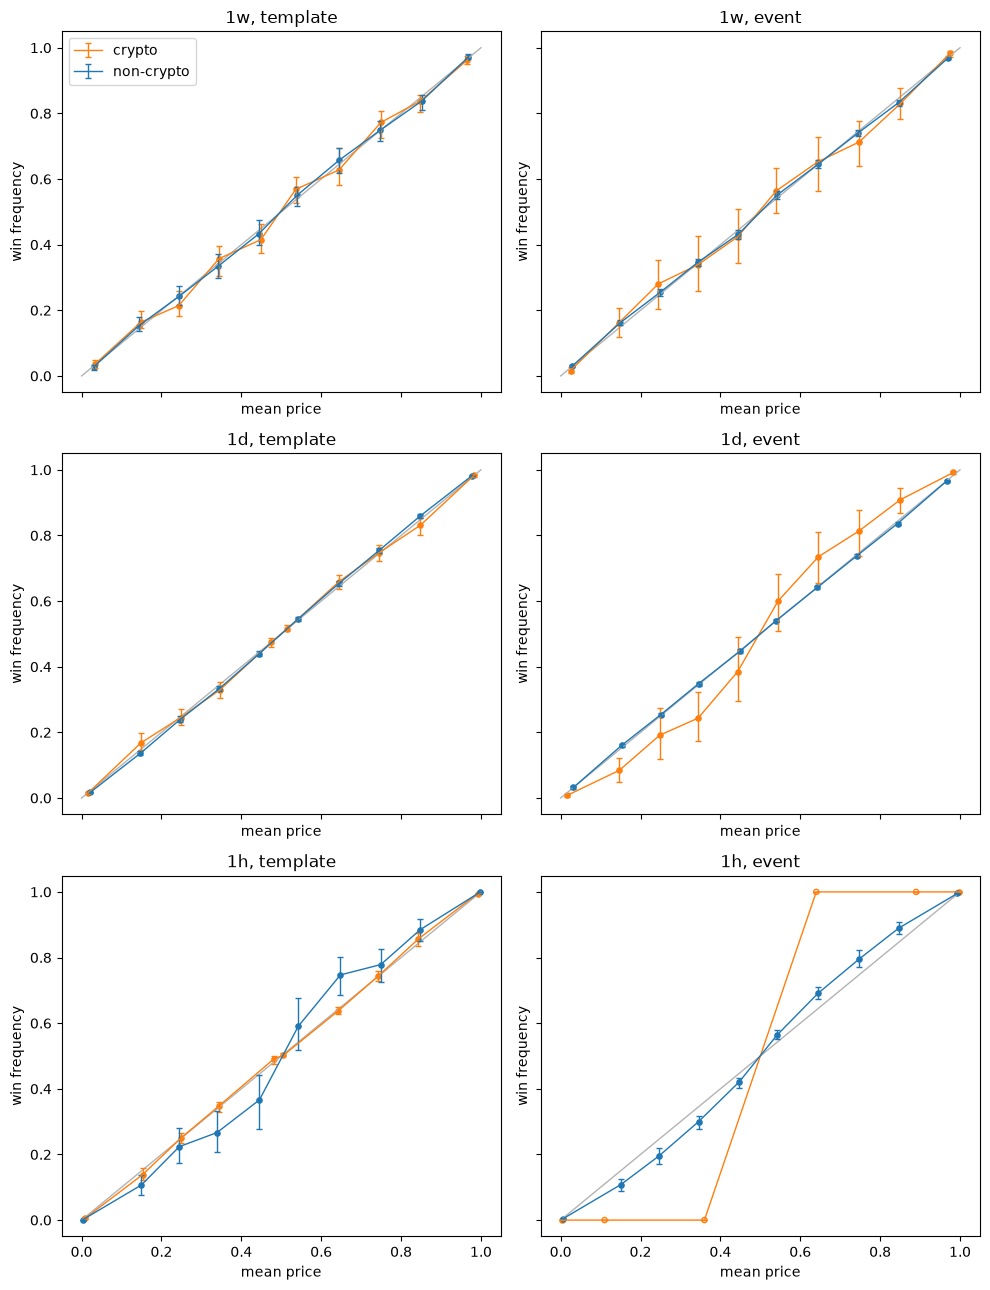

In [5]:
curves_sym = curve_grid(True, RESULTS / "rq1_curves_symmetrized.png")
curves_sym.to_csv(RESULTS / "rq1_curves_symmetrized.csv", index=False)

## 4. Sensitivities (Section 5, D7.7)

Each refits the six interaction models; coefficients and 95% CIs only, no p-values.
5.6 skips a cell-year with fewer than 30 clusters on either side.
Fits that are not estimable (D7.1) are blank in the table and flagged in
`results/rq1_sensitivities.csv`.


In [6]:
f = frame
sens_specs = {
    "5.1 no volume floor": (f[f["within_cap"]], "snap_price", "cluster_id"),
    "5.2 volume >= $10k": (f[f["within_cap"] & (f["volume_usd"] >= 10_000)], "snap_price", "cluster_id"),
    "5.3 5-min VWAP": (primary, "vwap_price", "cluster_id"),
    "5.4 no staleness cap": (f[f["volume_usd"] >= 1000], "snap_price", "cluster_id"),
    "5.5 event clustering": (primary, "snap_price", "event_id"),
    "5.7 no early closes": (primary[~primary["early_close"].astype(bool)], "snap_price", "cluster_id"),
}
cols = ["horizon", "format", "n_crypto", "n_noncrypto", "clusters_crypto", "clusters_noncrypto",
        "estimable", "interaction", "ci_low", "ci_high"]
sens = []
for name, (d, price_col, cluster_col) in sens_specs.items():
    sens.append(run_family(d, price_col, cluster_col)[cols].assign(sensitivity=name))
for year in sorted(primary["close_year"].unique()):
    t = run_family(primary[primary["close_year"] == year])
    t.loc[~t["testable"], ["interaction", "ci_low", "ci_high"]] = np.nan
    sens.append(t[cols].assign(sensitivity=f"5.6 year {year}"))
sens = pd.concat(sens, ignore_index=True)
sens.to_csv(RESULTS / "rq1_sensitivities.csv", index=False)
# Display masks fits that are not estimable (D7.1); the CSV keeps them with the flag.
shown = sens.assign(interaction=sens["interaction"].where(sens["estimable"]))
shown.pivot_table(index=["horizon", "format"], columns="sensitivity", values="interaction", dropna=False).round(3)

sensitivity       5.1 no volume floor  5.2 volume >= $10k  5.3 5-min VWAP  5.4 no staleness cap  5.5 event clustering  5.6 year 2023  5.6 year 2024  5.6 year 2025  5.6 year 2026  5.7 no early closes
horizon format                                                                                                                                                                                        
1d      event                   0.393               0.413           0.259                 0.436                 0.388          1.691          0.249          0.250          0.592                0.125
        template               -0.065               0.109          -0.047                -0.041                -0.060            NaN            NaN          0.044         -0.086                0.030
1h      event                     NaN                 NaN             NaN                 0.713                   NaN            NaN            NaN            NaN            NaN                  NaN
        template               -0.154              -0.183          -0.031                -0.319                -0.202            NaN            NaN            NaN         -0.262               -0.119
1w      event                   0.169               0.116           0.105                 0.187                 0.141          0.073          0.365          0.072          0.149                0.216
        template               -0.039              -0.071           0.087                -0.070                -0.048            NaN            NaN          0.053         -0.096                0.106